# <font color=orange>Lecture 11: Numerical Methods</font>



![](https://i.redd.it/8sycuf8srtq21.gif) <br>


## Numerical Methods:
Numerical methods are mathematical tools that approximate solutions to equations when algebraic methods are not possible. They are used to solve problems such as integrals, differential equations, and nonlinear equations. Numerical methods are used because computer algorithms can only perform arithmetic, not calculus. They are used to transform spatial and temporal derivatives into equations that computers can solve. Numerical methods work by constructing successive approximations that converge to the exact solution of an equation or system of equations. When a numerical method is implemented with a convergence check in a programming language, it is called a numerical algoritm. The Finite Element Method (FEM) is considered the most popular numerical method.

Numerical Methods are not limited by these but we will cover below methods:

    - Root Finding Methods: 
        a. Bracketed Methods (Bisection)
        b. Open Methods (Secant)
    - Numerical Differentitation:
        - Finite Difference Methods.
    - Numerical Integration:
        -Trapezoid Rule.
We need to learn the lambda function first to be able to utilize math functions. A lambda function is a small, anonymous function that can take any number of arguments but can only have one expression. The syntax for a lambda function is:


In [ ]:
 lambda arguments : expression

arguments: A comma-separated list of arguments that the function will take.   
expression: The expression that the function will evaluate and return.

In [2]:
# EXAMPLE
double = lambda x: x * 2
result = double(5)
print(result)

10


Lambda functions are often used with higher-order functions, which take other functions as arguments or return functions as results. Common examples of higher-order functions include:

map(): Applies a function to each element of an iterable and returns a new iterable.

filter(): Filters elements from an iterable based on a predicate function and returns a new iterable.

sorted(): Sorts an iterable using a custom comparison function.

##### Lambda functions are concise and useful for short, one-time functions.
##### Lambda functions can have multiple arguments, but they can only have one expression.


In [12]:
numbers = [1, 2, 3, 4, 5]

# Using map() to square each number
squared_numbers = list(map(lambda x: x**2, numbers))
print(squared_numbers)

# Using filter() to find even numbers
even_numbers = list(filter(lambda x: x % 2 == 0, numbers))
print(even_numbers)

# Using sorted() to sort numbers in descending order
sorted_numbers = sorted(numbers, key=lambda x: -x)
print(sorted_numbers)

[1, 4, 9, 16, 25]
[2, 4]
[5, 4, 3, 2, 1]


### General Approach for Numerical Methods

In numerical methods, a while loop is commonly used for iterative processes, where you need to repeat a set of calculations until a certain condition is met. Here's a general structure and explanation of how a while loop is typically set up in this context:

In [ ]:
es = ...  # Define a stopping criterion
error = 100  # Initialize error with a high number like 100 
#so we can get in to the while loop.

# Start the while loop
while error > es:
    # Perform calculations
    new_value = ...  # Update your variable using some numerical method
    
    # Calculate approx. relative error
    error = abs((new_value - previous_value)/new_value)  # or any appropriate error measure
    
    # Update previous value for the next iteration
    previous_value = new_value

# Result is stored in new_value

### Root Finding Methods:
#### We will learn one bracketed (BiSection Method) and one open (Secant Method) to find root of a given function numerically. 

### BiSection Method

The bisection method is a numerical algorithm used to find the root of a continuous function within a given interval. It works by repeatedly dividing the interval in half and checking the sign of the function at the endpoints of the new intervals.

#### Steps:

1. Define the function: Write a Python function that represents the equation whose root you want to find.
2. Define the interval: Specify the initial interval [a, b] where you expect the root to lie.
3. Check for a root: Evaluate the function at the endpoints of the interval. If the function changes sign between the endpoints, then a root exists within the interval.
4. Calculate the midpoint: Find the midpoint of the interval using c = (a + b) / 2.
5. Check for a root at the midpoint: Evaluate the function at the midpoint. If the function changes sign between the midpoint and one of the endpoints, then the root lies in that half-interval.
6. Repeat: Update the interval to the half-interval that contains the root and repeat steps 4-5 until the desired accuracy is achieved or a maximum number of iterations is reached.

1.125 33.33333333333333 1
1.3125 14.285714285714285 2
1.40625 6.666666666666667 3
1.453125 3.225806451612903 4
1.4296875 1.639344262295082 5
1.41796875 0.8264462809917356 6
1.412109375 0.4149377593360996 7
1.4150390625 0.2070393374741201 8
1.41357421875 0.10362694300518134 9
1.414306640625 0.05178663904712584 10
1.4139404296875 0.0259000259000259 11
The root in interval [0,1.5] is 1.41394


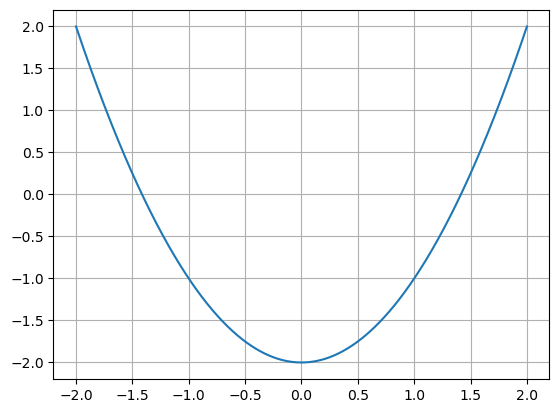

In [14]:
# EXAMPLE
import numpy as np
import pylab as pl
#%% plot 
f=lambda x: x**2-2
x=np.linspace(-2,2,1000)

pl.plot(x,f(x))
pl.grid()
lower=0;upper=1.5
#%% initialize
xl=lower; xu=upper #select from plot
xm=(xl+xu)/2 #first guess
es=0.05
ea=100 
i=0

#%% iterative
while ea>es:   
    i=i+1
    if f(xl)*f(xm)>0: 
        xl=xm
    else:
        xu=xm
        
    old=xm  #save old guess
    xm=(xl+xu)/2 #new guess
    ea=abs((xm-old)/xm)*100 #relative error
    print(xm,ea,i)
#%% print   

print('The root in interval [{0:g},{1:g}] is {2:.5f}'.format(lower,upper,xm))

### Secant Method
The secant method is a numerical algorithm used to find the root of a continuous function. It works by approximating the root using a sequence of points that lie on the function's graph. It is an open method so no need for bracketing the root. 

Steps:

1. Choose two initial points: Select two initial points, x0 and x1, that are close to the root.
2. Calculate the next approximation: Use the formula:
x2 = x1 - f(x1) * (x1 - x0) / (f(x1) - f(x0))
where f is the function whose root we're trying to find.
3. Update the points: Replace x0 with x1 and x1 with x2.
4. Repeat: Repeat steps 2 and 3 until the desired accuracy is achieved or a maximum number of iterations is reached.

1 100.99999999999986 99.00990099009901
2 1.0098039215686185 9901.94174757289
3 1.019413743392591 0.9426812112608068
4 1.4928945514756762 31.71562302341216
5 1.4018491402524673 6.4946654107739406
6 1.4138774894541306 0.8507348968620465
7 1.4142150381368959 0.023868271349309425
The root lies at 1.4142150381


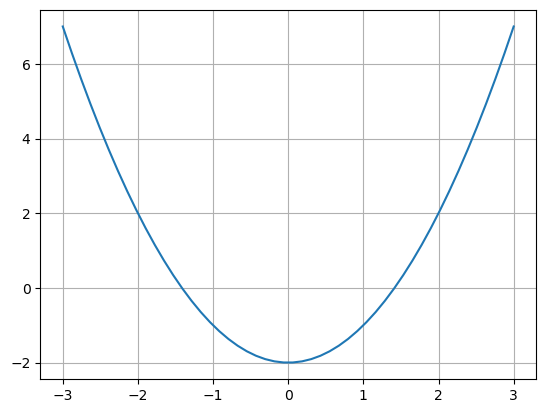

In [10]:
# EXAMPLE
import numpy as np
import pylab as pl
f=lambda x: x**2-2 #rootfinding function

x=np.linspace(-3,3); 
y=f(x)
pl.plot(x,y); 
pl.grid()
# From plot select two initial guesses close 
# to the root. This is an open method, so the
# two guesses may or may not include the root

xim1=-0.99; xi=1 # initial guesses
#initialze
es=0.05
ea=100
i=0; maxiter=100
while ea>es and i<maxiter:
    i=i+1
    xip1=xi-f(xi)*(xim1-xi)/(f(xim1)-f(xi))
    ea=abs((xip1-xi)/xip1)*100
    print(i, xip1, ea)
    #update values
    xim1=xi
    xi=xip1

#print results     
if i==maxiter:
    print('Maximum number of iterations reached')
else:
    print('The root lies at {:.10f}'.format(xip1))
    


### NUMERICAL DIFFERENTIATION:

#### Finite Difference method:

The finite difference method is a numerical technique used to approximate the solution of differential equations. It involves discretizing the domain of the equation into a grid of points and approximating the derivatives using finite differences.

Basic Steps:

1. Discretize the domain: Divide the domain of the differential equation into a grid of points with a uniform or non-uniform step size.
2. Approximate derivatives: Use finite difference formulas to approximate the derivatives at each grid point. Common formulas include:
    - Forward difference: f'(x) ≈ (f(x+h) - f(x)) / h
    - Backward difference: f'(x) ≈ (f(x) - f(x-h)) / h
    - Central difference: f'(x) ≈ (f(x+h) - f(x-h)) / (2h)
3. Create a system of equations: Substitute the finite difference approximations into the differential equation to create a system of algebraic equations.
4. Solve the system of equations: Solve the system of equations using numerical methods like Gaussian elimination or iterative methods.


![](https://upload.wikimedia.org/wikipedia/commons/thumb/a/a9/Finite_difference_method_2.svg/744px-Finite_difference_method_2.svg.png?20171111123314) <br>

#### Key points:

- The accuracy of the finite difference method depends on the step size and the order of the finite difference formula.
- For higher-order differential equations or complex geometries, more advanced finite difference techniques may be required. But not in the scope of this course. 

actual = 27.0000


h = 0.1

forward: 27.9100, error = 3.37 %

backward: 26.1100, error = 3.30 %

centered: 27.0100, error = 0.04 %

*****************************
h = 0.01

forward: 27.0901, error = 0.33 %

backward: 26.9101, error = 0.33 %

centered: 27.0001, error = 0.00 %

********************************


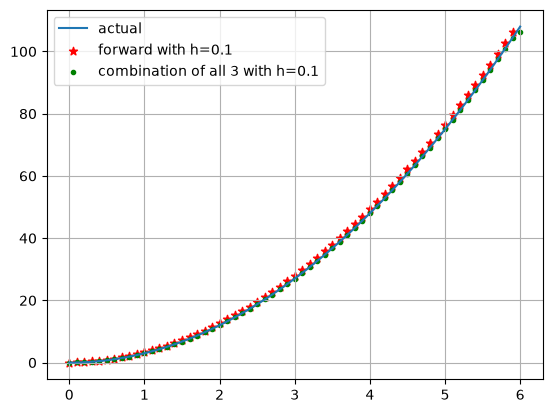

In [1]:
#EXAMPLE
import numpy as np

f=lambda x: x**3
df=lambda x: 3*x**2 #actual derivative

#estimate derivative at x = 3,
xi = 3
df_true=df(xi)
print('actual = {:.4f}\n\n'.format(df_true))

#using h = 0.1
h = 0.1
xi_m= xi - h
xi_p = xi + h

df_xi_for= (f(xi_p)-f(xi))/h
err_for=abs((df_true-df_xi_for)/df_true)*100

df_xi_back= (f(xi)-f(xi_m))/h
err_back=abs((df_true-df_xi_back)/df_true)*100

df_xi_centered = (f(xi_p)-f(xi_m))/(2*h)
err_cent=abs((df_true-df_xi_centered)/df_true)*100

print('h = 0.1\n')
print('forward: {:5.4f}, error = {:3.2f} %\n'.format(df_xi_for,err_for))
print('backward: {:5.4f}, error = {:3.2f} %\n'.format(df_xi_back,err_back))
print('centered: {:5.4f}, error = {:3.2f} %\n'.format(df_xi_centered,err_cent))
print('*****************************')

#decrease the step size
#estimate derivative at x = 3, using h = 0.01
h = 0.01
xi_m= xi - h
xi_p = xi + h

df_xi_for= (f(xi_p)-f(xi))/h
err_for=abs((df_true-df_xi_for)/df_true)*100

df_xi_back= (f(xi)-f(xi_m))/h
err_back=abs((df_true-df_xi_back)/df_true)*100

df_xi_centered = (f(xi_p)-f(xi_m))/(2*h)
err_cent=abs((df_true-df_xi_centered)/df_true)*100

print('h = 0.01\n')
print('forward: {:5.4f}, error = {:3.2f} %\n'.format(df_xi_for,err_for))
print('backward: {:5.4f}, error = {:3.2f} %\n'.format(df_xi_back,err_back))
print('centered: {:5.4f}, error = {:3.2f} %\n'.format(df_xi_centered,err_cent))
print('********************************')
x=np.arange(0,6.0001,0.1)
fx = f(x)
df_for=np.diff(fx)/0.1
df_gr=np.gradient(fx,0.1)

#Let's try to plot our results
import pylab as pl
pl.figure(1)
xx=np.linspace(0,6,100)
pl.plot(xx,df(xx))
pl.scatter(x[0:-1],df_for,marker='*', color='r' )
pl.scatter(x,df_gr,marker='.', color='green')
pl.legend(['actual','forward with h=0.1','combination of all 3 with h=0.1'])
pl.grid()


### NUMERICAL INTEGRATION:

#### Trapezoid method:
The trapezoid method is a numerical integration technique used to approximate the definite integral of a function. It works by approximating the area under the curve of the function using trapezoids.   

Steps:

1. Divide the interval: Divide the interval of integration into n subintervals of equal width h = (b - a) / n.
2. Approximate the area: For each subinterval, approximate the area under the curve using a trapezoid. The area of a trapezoid is calculated as:
A = (h/2) * (f(x_i) + f(x_i+1))
where x_i and x_i+1 are the endpoints of the subinterval and f is the function being integrated.
3. Sum the areas: Sum the areas of all the trapezoids to obtain the approximate integral.

   - The accuracy of the trapezoid method can be improved by increasing the number of subintervals.

![](https://miro.medium.com/v2/resize:fit:1200/1*eXjZQAETZqEMXrwzBj3lgg.gif) <br>



exact value= -1.4260247563462674
True integration= -1.4260247563462674
trapz result= -1.411956046525754
Composite trapezoidal result= -1.411956046525751


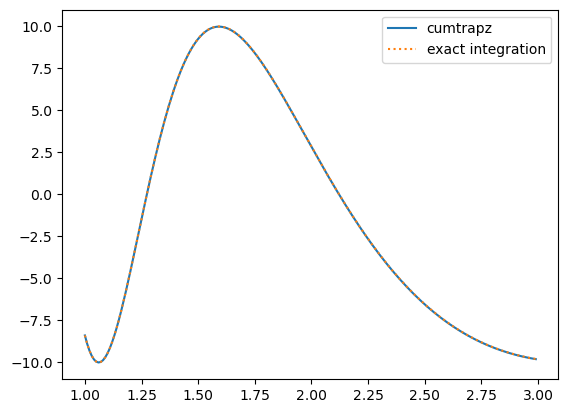

In [88]:
# EXAMPLE
import numpy as np
#an example using a function that is "difficult" to integrate
f=lambda x: 100/x**2*np.sin(10/x)
exact =lambda x: 10*np.cos(10/x) #analytical solution
#exact value of definite integral of (100/x^2)*sin(10/x) from 1 to 3
I_ex = exact(3)-exact(1)
print('exact value=', I_ex)

h=0.01
# Constructing data from the function
x = np.arange(1,3,h)
y=f(x)

#=====================
print('True integration=', I_ex)
#built-in function 'trapz':
I_trz=np.trapz(y,x) # note the order (y,x)!!
print('trapz result=', I_trz)

n=len(y)
# can also be done using the following two syntaxes
I_trap=h/2 * (y[0]+ 2* np.sum(y[1:-1])+ y[-1]) # when you know that there are 13 points (indexed 0-12) in the array 
print('Composite trapezoidal result=', I_trap)

from scipy.integrate import cumulative_trapezoid 

cumulativeIntegral=cumulative_trapezoid(f(x),x, initial=0)

import pylab as plt

plt.plot(x,cumulativeIntegral-8.39071529,label='cumtrapz')
plt.plot(x,exact(x),label='exact integration',linestyle = 'dotted')
plt.legend()
